# CS1 - Full Formation Evaluation of a North Sea Discovery Well (30/6-5)

**Petrophys Case Studies - Project 1**

This is not a single-module tutorial. It is an end-to-end *interpretation project*
with a concrete deliverable: a formation evaluation of a discovery well and a
formation-by-formation recommendation of **where to perforate**.

**What you will learn**

- How to run one auditable interpretation with `pp.interpret` and read its step trace.
- How to check *where* the net-pay flag fired before trusting any total.
- How to roll the result up by formation with `result.formation_summary(..., rank="formation")`
  and turn it into a ranked completion plan.
- Why a whole-well net-pay total can mislead, and how choosing the reservoir interval fixes it.

**Prerequisites.** Lessons 00-01 (loading data), 07 (water saturation), 09 (net pay - it also
reconciles this well's Rw) and 10-11 (workflow traces and formation summaries). The base
install is enough; no optional extras are needed.

We follow the standard case-study spine:

1. **The brief** - the business question and why it matters.
2. **The well and data** - what we have, what is missing.
3. **Workflow plan** - the chain of interpretation steps and why in this order.
4. **Execution** - one `pp.interpret` run, with its step trace used as an audit, and a check
   of where the pay flag fired.
5. **Integrated result** - a per-formation results table and a multi-track interpretation plot.
6. **Interpretation and deliverable** - what the numbers mean, and the ranked completion picks.
7. **Limitations and assumptions** - honest caveats.
8. **Appendix** - how to re-run on another well and hand off the results.

> This lesson *uses* the library end-to-end and references the Part A / Part B tutorials for
> the underlying physics (Vcl from GR, density-neutron porosity, Archie saturation, net-pay
> cutoffs). It does not re-teach those basics.

## Part 1 - The brief

> **From:** Subsurface team lead, North Sea development asset.
> **Subject:** Well 30/6-5 - full formation evaluation and completion recommendation.
>
> We have just finished logging discovery well **30/6-5** (Oseberg area, Norwegian North Sea).
> Wireline is in. Before we design the completion, I need a **defensible, auditable formation
> evaluation** of the whole logged section and a **ranked list of intervals to perforate**.
> Tell me which zones are pay, how good they are (porosity, water saturation, permeability),
> and where you would put the guns first. Flag anything you had to assume.

**Why it matters.** The completion decision commits real money. Perforate the wrong zone and you
produce water or nothing; miss a good zone and you leave reserves behind. The recommendation has
to be traceable - every cutoff and every assumed parameter must be visible so the reservoir
engineer can challenge it. That auditability is exactly what the *dynamic workflow* trace gives us.

**The deliverable (three artifacts):**

- **(a)** a multi-track interpretation / log plot summarizing the evaluation;
- **(b)** a per-formation results table (net pay, average PHIE, average Sw, hydrocarbon pore
  thickness index);
- **(c)** a ranked list of candidate completion intervals with written rationale.

## Part 2 - The well and the data

**Well 30/6-5** is a GeoLink clastic well from the Oseberg area, logged in **metres**. It penetrates
the Norwegian North Sea section from the shallow Nordland and Hordaland groups, through the
Cretaceous and the Viking Group mudstones (Draupne and Heather formations), into the Middle Jurassic
**Brent Group** sands - labelled `BAAT GP.` in the bundled tops, with the **Ness** and **Etive**
formations inside it - and on through the Dunlin Group to the **Statfjord Formation** near total depth.

What we have and what we are missing drives every modelling choice below, so we inventory it first.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys as pp

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
print("petrophys", pp.__version__)

# Read the LAS on its own. The bundled formation tops are kept separate and passed
# to the plot and to the per-formation summary later (see the note below).
well = pp.read(pp.sample("30_6-5"))
TOPS = pp.sample("formations_30_6-5")

print("Well name      :", well.name)
print("Field          :", well.header.field)
print("Depth interval : {:.1f} - {:.1f} {}".format(well.top, well.bottom, well.depth_unit))
print("Samples        : {} at step {:.4f} {}".format(well.n_samples, well.step, well.depth_unit))
print("Curves         :", ", ".join(well.curves))

petrophys 3.0.0


Well name      : 30/6-5
Field          : OSEBERG ØST
Depth interval : 176.6 - 3556.1 m
Samples        : 22176 at step 0.1524 m
Curves         : LITHOLOGY_GEOLINK, CALI, DRHO, NPHI, RHOB, PEF, GR, DTC, DTE, RDEP, SP, RSHA, RMED, BS, PHIC, GDEN, KH_CORE, KV_CORE, SWC, SOC


### A first plot comes before any interpretation

Before applying the study's assumptions, look at the raw LAS. Formations and lithology are optional
inputs, and this study makes two deliberate choices about them:

- It keeps the vendor lithology embedded in the LAS (`LITHOLOGY_GEOLINK`). Attaching an external
  lithology table with `pp.read(..., lithology=...)` would change the lithology source the
  interpretation uses - a model change, not styling. The [own-data tutorial](../own_data.ipynb)
  demonstrates that route.
- It keeps the formation tops *out of* the well object and passes `TOPS` only to the plot and to
  `formation_summary`. Tops attached with `pp.read(..., formations=...)` also drive
  group-by-group and formation-by-formation core-permeability calibration in `pp.interpret`
  (a formation's model takes precedence over its group's). This study keeps one whole-well core
  calibration instead; exercise 3 explores the alternative.

[repository]/src/petrophys/preprocessing/standardization/curve_standardizer.py:393: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]/src/petrophys/preprocessing/standardization/curve_standardizer.py:393: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


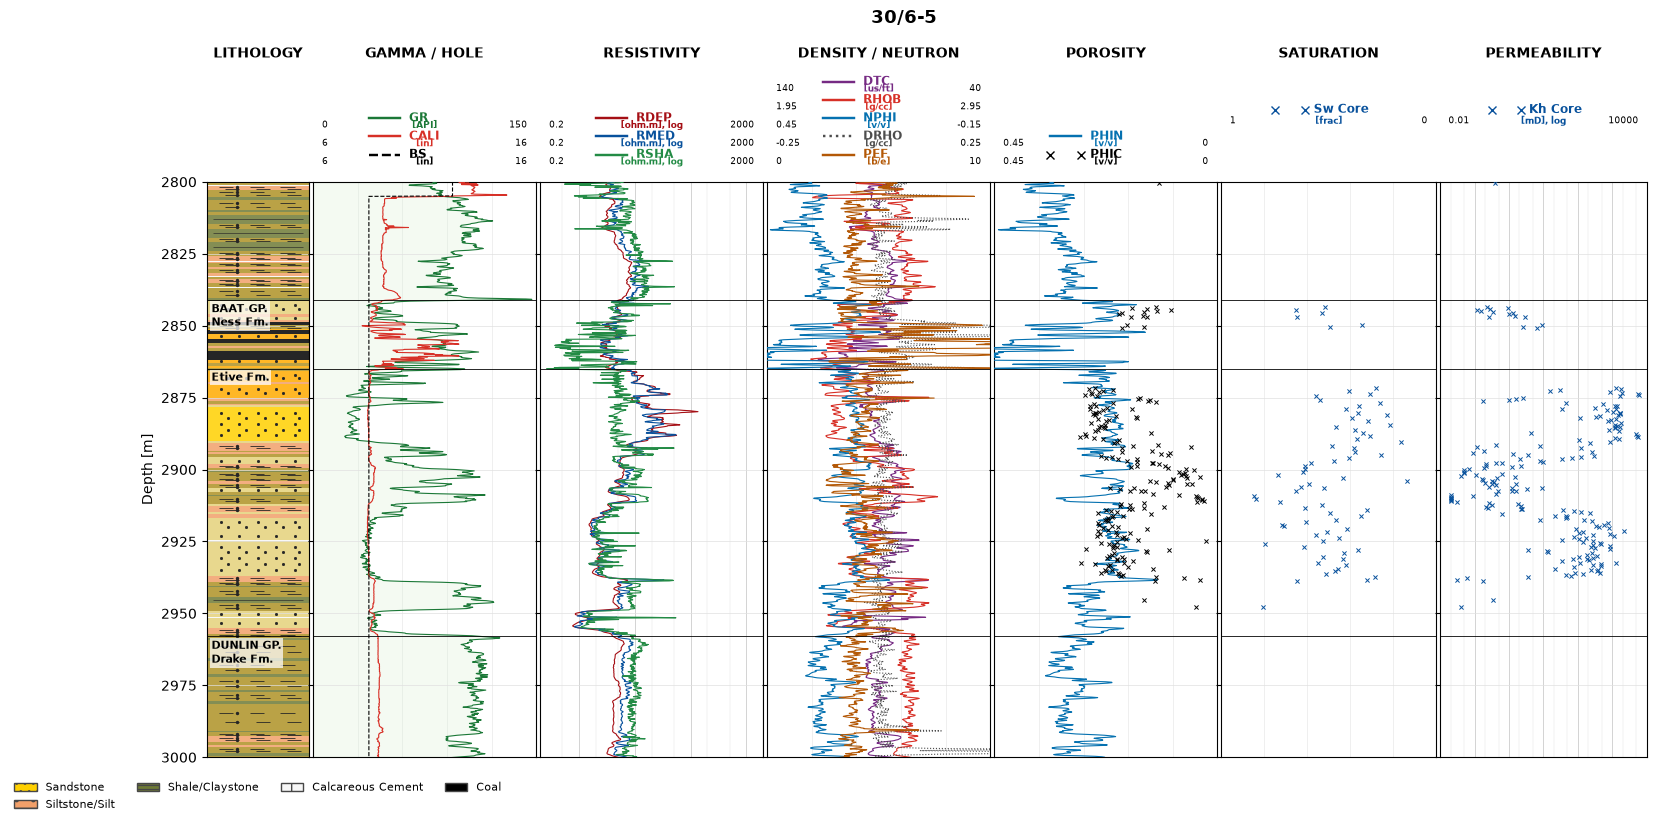

Display warnings: ['No geology depth_reference supplied; assumed to match the well (not independently verified).', 'No geology datum supplied; assumed to match the well (not independently verified).', "SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units."]


In [2]:
raw_viewer = pp.plot(well, depth_range=(2800, 3000), formation_tops=TOPS, figsize=(15, 8))
raw_viewer.show()
raw_viewer.close()
print("Display warnings:", raw_viewer.warnings)

### Data readiness check

The plot also reported some expected messages:

- The tops file records no depth reference or datum, so Petrophys assumes they match the well and
  says so.
- The core water saturation `SWC` (and the core oil saturation `SOC`) is stored in percent although
  the LAS labels it `frac`. Petrophys divides it by 100 on a copy, and raises a `UserWarning` for
  each curve (shown above) so you can verify the source file.

Those two unit warnings would repeat every time a copy of this well is standardized - in the
plot, in `pp.interpret` and in the appendix re-run. Now that they are explained, the next cell
filters exactly those two messages (and nothing else) to keep the output readable.

Next we split the available curves into the log families the interpretation needs, and note the
gaps. This LAS release carries the operator's **parameter block** in the header (Rw, Rmf, BHT, mud
filtrate chlorides), so the environment does not have to be invented - though Part 3 shows one of
those values needs care before use. The most consequential *data* gap is the photoelectric factor
(PEF), which helps discriminate lithology but is only recorded over a narrow deep interval. Both
facts are revisited in Part 7.

In [3]:
import warnings

# Explained above: SWC/SOC are stored in percent although labelled 'frac'. Hide only
# these repeats; every other warning stays visible.
warnings.filterwarnings(
    "ignore", message=r"(SWC|SOC): inferred percent core saturation", category=UserWarning
)

families = {
    "Gamma ray / clay":   ["GR", "SP"],
    "Porosity (D/N/S)":   ["RHOB", "NPHI", "DTC"],
    "Resistivity":        ["RDEP", "RMED", "RSHA"],
    "Lithology aids":     ["PEF", "DRHO", "LITHOLOGY_GEOLINK"],
    "Borehole / caliper": ["CALI", "BS"],
    "Core":               ["PHIC", "KH_CORE", "SWC", "SOC"],
}
for fam, mnems in families.items():
    present = [m for m in mnems if well.has_curve(m)]
    missing = [m for m in mnems if not well.has_curve(m)]
    print("{:22s} present: {:35s} missing: {}".format(
        fam, ", ".join(present) if present else "-",
        ", ".join(missing) if missing else "-"))

print()
# PEF live interval - it is only recorded over the deep section.
depth = well.depth
pef_live = depth[np.isfinite(well.get("PEF").data)]
print("PEF live interval : {:.0f} - {:.0f} m (of {:.0f} - {:.0f} m logged)".format(
    pef_live.min(), pef_live.max(), depth.min(), depth.max()))

print("Header ~Params block:")
for k in ("RW", "RMF", "BHT", "CLFL"):
    v = well.get_parameter(k)
    u = well.get_parameter(k + "__UNIT") or ""
    d = well.get_parameter(k + "__DESCR") or ""
    print("   {:5s}= {:>10} {:6s} {}".format(k, v, u, d))

Gamma ray / clay       present: GR, SP                              missing: -
Porosity (D/N/S)       present: RHOB, NPHI, DTC                     missing: -
Resistivity            present: RDEP, RMED, RSHA                    missing: -
Lithology aids         present: PEF, DRHO, LITHOLOGY_GEOLINK        missing: -
Borehole / caliper     present: CALI, BS                            missing: -
Core                   present: PHIC, KH_CORE, SWC, SOC             missing: -

PEF live interval : 2784 - 3176 m (of 177 - 3556 m logged)
Header ~Params block:
   RW   =        0.7 ohmm   Rw
   RMF  =       0.08 ohmm   Rmf
   BHT  =      126.0 degC   Max Recorded Bottom Hole Temperature
   CLFL =    20366.0 mg/l   Mud Filtrate Cl


## Part 3 - The workflow plan

We use the library's **dynamic workflow**, called through `pp.interpret`, as the interpretation
backbone. It inspects the curves that are present and runs only the modules it can support, in
petrophysical order, recording a **step-by-step trace** we will use as the audit.

The core chain it executes for 30/6-5 (each step references the tutorial that teaches it):

| # | Step | What it does | Key inputs |
|---|------|--------------|-----------|
| 1 | Temperature | Builds a temperature profile from an assumed surface temperature and the header BHT | depth, BHT |
| 2 | Bad-hole | Flags washed-out / rugose hole from CALI vs BS | CALI, BS, DRHO |
| 3 | Vcl | Volume of clay from GR, SP and neutron-density | GR, SP, RHOB, NPHI |
| 4 | Porosity | Density-neutron total porosity PHIT and effective PHIE | RHOB, NPHI |
| 5 | Lithology | Multi-mineral solve (quartz / calcite / dolomite / clay) | RHOB, NPHI, PEF |
| 6 | Core correction | Ties log porosity/perm to core (PHIC, KH_CORE) | PHIC, KH_CORE |
| 7 | Rw | Formation-water resistivity, temperature-corrected along the profile | Rw + its temperature |
| 8 | Saturation | Water saturation Sw (Archie family, auto-routed) | RDEP, PHIE, Rw |
| 9 | Permeability | Log permeability, core-calibrated where possible | PHIE, core |
| 10 | Rock quality | RQI / FZI flow indicators | PHIE, PERM |
| 11 | Net pay | 3-stage cutoffs -> net rock / net reservoir / net pay | Vcl, PHIE, Sw |

The table lists the core chain. The engine also runs housekeeping and extra steps - curve
normalization, input-context selection, Rmf and shale resistivity (Rcl), invasion, bulk-volume water
(BVW), the moveable-hydrocarbon index (MHI) and final permeability / rock-quality passes. Part 4
prints the exact list it ran.

We then roll the sample-by-sample answer up to a **per-formation** summary using the bundled
formation tops, and finally turn that into a completion recommendation.

**Model choices and why:**

- **`lithology_domain="clastic"`, `matrix_type="sandstone"`.** 30/6-5 is a siliciclastic Jurassic
  section; the reservoirs are the Brent and Statfjord sands.
- **Saturation model = auto.** We let the workflow route to the appropriate Archie-family model.
  Case study CS5 does a dedicated Sw-model sensitivity; here we take the workflow's routed answer.
- **Environment from the header, with one reconciliation.** The LAS header records both a BHT and
  an Rw, so neither has to be invented. The printed Rw needs care (next cell), and the surface
  temperature is the only environmental input we assume. Rw is the single biggest lever on Sw.

### Parameters: from the header, applied with care

The header's parameter block gives us BHT (126 degC), Rmf (0.08 ohm.m), mud filtrate chlorides
(20,366 mg/l) and a stated **Rw of 0.70 ohm.m** with no temperature basis. That last value cannot
be used at face value: plugged into Archie at reservoir conditions it wets out the entire well
(Sw far above 1 everywhere), which contradicts both the operator's own completion-report
evaluation and the NPD fact page for this well (oil logged from 2841 m down to 2899 m, OWC from
pressure data at 2907 m). Lesson 09 back-calculates the value the operator's evaluation actually
used: **Rw = 0.070 ohm.m at reservoir temperature (230 degF)** - consistent with the header figure
being a report-table printing of that number.

We therefore pass `rw=0.070` **and** `rw_meas_temp_f=230`. The temperature matters: without it,
Petrophys assumes the Rw was measured at 75 degF and corrects it to a much lower value at depth,
which changes Sw strongly.

The surface reference temperature still has to be assumed. Every value below lands in the run
settings and therefore in the audit trace.

In [4]:
from petrophys.evaluation import STANDARD_CUTOFFS

# --- Environment from the LAS header (plus two documented decisions) ---------
BHT_F = float(well.get_parameter("BHT")) * 9.0 / 5.0 + 32.0   # header BHT is in degC
TD_FT = well.bottom / 0.3048                                  # temperature gradient needs TD in ft

ENV = {
    "surface_temp_f": 50.0,          # ~10 degC North Sea seabed - an assumption
    "bht_f":          round(BHT_F, 1),
    "td_ft":          round(TD_FT, 0),
    "rw":             0.070,         # header prints 0.70; reconciled value (lesson 09)
    "rw_meas_temp_f": 230.0,         # temperature at which that Rw applies
}
# --- Net-pay cutoffs: the clastic curriculum standards, set explicitly so the
# --- values are recorded in the run settings and visible in the audit.
CUTOFFS = dict(STANDARD_CUTOFFS["clastic"])

SETTINGS = dict(lithology_domain="clastic", matrix_type="sandstone", **ENV, **CUTOFFS)

print("Interpretation settings:")
for k, v in SETTINGS.items():
    print("   {:16s} = {}".format(k, v))

Interpretation settings:
   lithology_domain = clastic
   matrix_type      = sandstone
   surface_temp_f   = 50.0
   bht_f            = 258.8
   td_ft            = 11667.0
   rw               = 0.07
   rw_meas_temp_f   = 230.0
   vcl_cutoff       = 0.4
   phie_cutoff      = 0.08
   sw_cutoff        = 0.6


## Part 4 - Execution: run the interpretation and read its audit trace

One call runs the whole chain: `pp.interpret(well, **SETTINGS)`. Every keyword is a validated
`DynamicWorkflowConfig` setting, so a typo raises an error instead of being ignored.
`pp.interpret` works on a **copy**: `well` stays the raw LAS, and the interpreted curves live on
`result.well`. (The lower-level `pp.run_dynamic_workflow` adds curves to the well you pass; we do
not need that here.)

The returned result records which steps executed, which were skipped and why, the computed Rw, and
a full per-step trace. We treat that trace as the **interpretation audit** - it is what makes the
recommendation defensible.

In [5]:
result = pp.interpret(well, **SETTINGS)
result.raise_for_errors()
interp = result.well          # the interpreted copy; `well` is unchanged

print("Status          :", result.status)
print("Steps executed  :", len(result.steps_executed))
print("Steps skipped   :")
for name, reason in result.specific_steps_skipped.items():
    print("   - {}: {}".format(name, reason))
print("Warnings        :", result.warnings or "none")

rw = np.asarray(result.rw_computed, dtype=float)
print("Rw along the well: {:.3f} - {:.3f} ohm.m (from {} ohm.m at {} degF)".format(
    np.nanmin(rw), np.nanmax(rw), ENV["rw"], ENV["rw_meas_temp_f"]))

Status          : interpreted
Steps executed  : 20
Steps skipped   :
   - spectral_gamma: Not run by the interpretation workflow; use petrophys.interpretation.geochemistry.interpret_spectral_gamma directly
   - elemental_spectroscopy: Not run by the interpretation workflow; use petrophys.interpretation.geochemistry.interpret_elemental_spectroscopy directly
   - hc_correction: apply_hc_correction=False (hydrocarbon correction is opt-in)
   - porosity_refinement: Not run by the interpretation workflow; porosity is computed once in the porosity step
Warnings        : none
Rw along the well: 0.062 - 0.247 ohm.m (from 0.07 ohm.m at 230.0 degF)


### The step-by-step audit

One row per executed step, with its method and first logged decision. Read it top-to-bottom: it is
the paper trail from raw logs to net pay. `result.print_trace()` prints every parameter and decision
(long - try it yourself), and `result.to_json(path)` saves the complete trace for a reviewer.

In [6]:
trace = result.to_dataframe()
trace["First decision"] = (
    trace["Decisions"].str.split(" | ", regex=False).str[0].str.slice(0, 72)
)
print(trace[["Step", "Status", "Method", "First decision"]].to_string(index=False))

                 Step Status                                      Method                                                           First decision
        normalization     OK        curve_alias_and_unit_standardization     Standardized curve units, nulls, and plausible ranges before routing
        input_context     OK                 validated_geology_selection               Selected vendor lithology; alternate sources were retained
          temperature     OK                    linear_gradient_from_BHT                       Temperature profile anchored to BHT metadata/input
             bad_hole     OK                          caliper_drho_flags                              12631 bad-hole samples flagged out of 22176
                vclay     OK                                      linear                                           GR_min = 20.0 (user, P5 of GR)
                  rcl     OK                   lithology_shale_median_rt          Rcl = 2.91 ohm.m (median RT in shale litho

Four steps set the pay flag directly: clay volume, Rw, saturation and net pay. Their key decisions
deserve a closer read - how VCL was combined, which Rw was used, which saturation model ran at how
many depths, and how many samples passed each cutoff.

In [7]:
# The decisions that matter most for the pay flag, picked by their leading text.
KEY_DECISIONS = {
    "vclay": ("GR_min", "GR_max", "Final VCL"),
    "rw": ("Rw",),
    "saturation": ("Model selected", "Depth routing"),
    "net_pay": ("NET_",),
}
for sr in result.steps_executed:
    if sr.step in KEY_DECISIONS:
        picked = [d for d in sr.decisions if d.startswith(KEY_DECISIONS[sr.step])] or sr.decisions[:3]
        print("[{}] method: {}".format(sr.step, sr.method))
        for decision in picked:
            print("    -> " + decision)

[vclay] method: linear
    -> GR_min = 20.0 (user, P5 of GR)
    -> GR_max = 100.0 (user, P95 of GR)
    -> Final VCL = min(available methods), range: 0.000 - 0.783
[rw] method: user_provided_temperature_profile_corrected
    -> Rw directly corrected from 0.0700 ohm.m @ 230F with Arps along the temperature profile
[saturation] method: archie+indonesia+dual_water
    -> Model selected: archie+indonesia+dual_water
    -> Depth routing counts: archie=21012, indonesia=1158, dual_water=6
[net_pay] method: cutoff_flags
    -> NET_ROCK: VCL < 0.4 -> 21012 samples (3201.2 m)
    -> NET_RES:  + PHIE_CC > 0.08 -> 20119 samples (3065.1 m)
    -> NET_PAY:  + SW < 0.6 -> 3707 samples (564.8 m)


### QC decision: check where the flag fired

The workflow wrote `NET_PAY`, `PHIE`, `SW` and `PERM` onto `result.well`. Before we trust any
number we check *where* the net-pay flag fired: the depth distribution should be geologically
sensible, and for a discovery well we can hold it against the public record.

In [8]:
depth = interp.depth
pay = interp.get("NET_PAY").data > 0.5
step = abs(interp.step)

print("Net pay flagged over the whole well: {:.1f} m".format(pay.sum() * step))
print("Distribution by depth (200 m bins):")
for lo in range(0, int(depth.max()) + 200, 200):
    n = int(np.sum(pay & (depth >= lo) & (depth < lo + 200)))
    if n:
        print("  {:4d}-{:4d} m : {:6.1f} m  {}".format(lo, lo + 200, n * step, "#" * min(50, n // 15)))

Net pay flagged over the whole well: 564.8 m
Distribution by depth (200 m bins):
     0- 200 m :   10.1 m  ####
   200- 400 m :   89.6 m  #######################################
   400- 600 m :  197.4 m  ##################################################
   600- 800 m :  106.3 m  ##############################################
   800-1000 m :   46.8 m  ####################
  1000-1200 m :    6.6 m  ##
  1200-1400 m :   28.9 m  ############
  1400-1600 m :    0.3 m  
  2000-2200 m :    0.8 m  
  2200-2400 m :    0.6 m  
  2400-2600 m :    2.4 m  #
  2600-2800 m :   32.6 m  ##############
  2800-3000 m :   39.0 m  #################
  3000-3200 m :    0.3 m  
  3200-3400 m :    3.0 m  #


The flag fires in two very different settings:

- **A compact block at about 2800-3000 m** - the Brent Group sands, the reason the well was
  drilled. Part 6 holds it against the public record.
- **The shallow overburden** - the Nordland and Hordaland groups above ~1900 m - plus flags in the
  Viking Group mudstones directly above the Brent. The well found no hydrocarbons in either.

A whole-well net-pay total therefore mixes a discovery with artefacts. The next cell summarizes the
flag by **group** (the coarsest level in the bundled tops) and compares the overburden samples with
the Brent pay.

In [9]:
groups = result.formation_summary(TOPS, rank="group")
unit = interp.depth_unit
NET_PAY = f"Net Pay ({unit})"
print(groups[["Formation", "Top", "Bottom", NET_PAY, "Avg PHIE", "Avg Sw", "Avg VCL"]]
      .round(3).to_string(index=False))

# Group boundaries from the tops table, not typed by hand.
overburden_base = groups.loc[groups["Formation"] == "HORDALAND GP.", "Bottom"].iloc[0]
brent = groups.loc[groups["Formation"] == "BAAT GP."].iloc[0]
BRENT_TOP, BRENT_BASE = float(brent["Top"]), float(brent["Bottom"])

shallow_pay = pay & (depth < overburden_base)
brent_pay = pay & (depth >= BRENT_TOP) & (depth < BRENT_BASE)
print()
print("Flagged pay above {:.0f} m (overburden): {:.1f} m = {:.0f}% of the whole-well total".format(
    overburden_base, shallow_pay.sum() * step, 100.0 * shallow_pay.sum() / max(pay.sum(), 1)))
print("Median over flagged samples      PHIE    VCL     SW   RDEP (ohm.m)  Rw (ohm.m)")
for label, mask in (("overburden", shallow_pay), ("Brent sands", brent_pay)):
    print("  {:28s} {:6.2f} {:6.2f} {:6.2f} {:10.1f} {:11.3f}".format(
        label,
        np.nanmedian(interp.get("PHIE").data[mask]), np.nanmedian(interp.get("VCL").data[mask]),
        np.nanmedian(interp.get("SW").data[mask]), np.nanmedian(interp.get("RDEP").data[mask]),
        np.nanmedian(rw[mask])))

       Formation    Top  Bottom  Net Pay (m)  Avg PHIE  Avg Sw  Avg VCL
    NORDLAND GP.  181.0   726.0      399.135     0.435   0.549    0.089
   HORDALAND GP.  879.0  1908.0       82.601     0.487   0.580    0.077
    ROGALAND GP. 1908.0  2203.0        0.762     0.413   0.577    0.109
    SHETLAND GP. 2203.0  2408.0        0.610     0.399   0.575    0.017
CROMER KNOLL GP. 2408.0  2452.0        0.000       NaN     NaN      NaN
      VIKING GP. 2452.0  2841.0       35.357     0.186   0.550    0.131
        BAAT GP. 2841.0  2958.0       38.710     0.231   0.357    0.062
      DUNLIN GP. 2958.0  3223.0        0.305     0.169   0.578    0.124

Flagged pay above 1908 m (overburden): 486.0 m = 86% of the whole-well total
Median over flagged samples      PHIE    VCL     SW   RDEP (ohm.m)  Rw (ohm.m)
  overburden                     0.44   0.09   0.56        2.6       0.187
  Brent sands                    0.23   0.00   0.32       12.1       0.073


#### Why the overburden passes the cutoffs - and why it is not pay

Compare the two rows above:

- **Porosity.** The Nordland and Hordaland sediments are young and poorly consolidated, so
  density-neutron porosity reads far higher than in the Brent sands, far above the 8 pu cutoff.
- **Clay volume.** The workflow takes VCL as the *minimum* of the GR, SP and neutron-density
  indicators (see the `vclay` decisions above). In soft, water-rich sediment that minimum can read
  clean even where the rock is shaly.
- **Water saturation.** The Rw was reconciled for the Brent brine and is corrected only for
  temperature, so it is higher in the cool shallow section. Shallow pore water need not have the
  reservoir's salinity, so Archie Sw there is not reliable; it only has to fall just under the
  0.60 cutoff for the flag to fire, and the deep resistivity is low - not a hydrocarbon signature.

None of this is pay: the NPD records no hydrocarbons in the overburden, and no engineer would
perforate it. The cure is not a special cutoff but **scope**: evaluate the reservoir formations, not
the whole hole. The same applies to the mudstones of the Viking Group (Draupne and Heather
formations), which seal the Brent and pick up patches of flags. This is why a whole-well net-pay
total is never the deliverable.

> Petrophys's default interpretation settings can flag the shallow section in the same way. Whatever
> settings you use, choose the reservoir interval explicitly - with
> `result.summary(top=..., bottom=...)` or a formation summary - before quoting pay.

## Part 5 - Integrated result

### 5a. Deliverable (b): the per-formation roll-up

`result.formation_summary(TOPS, rank="formation")` rolls the sample-by-sample interpretation up by
formation. The bundled tops mix two levels - groups such as `BAAT GP.` and the formations inside
them - so we ask for one level: `rank="formation"` keeps only formation picks and no depth is counted
twice. (Groups without formation picks, such as the Nordland Group, therefore do not appear; they
were covered by the group view in Part 4.) Each row gives gross, net rock / reservoir / pay, NTG,
averages over the pay and a hydrocarbon-pore-thickness index (HCPV).

In [10]:
fm_table = result.formation_summary(TOPS, rank="formation")

cols = ["Formation", "Top", "Bottom", f"Gross ({unit})", NET_PAY, "NTG",
        "Avg PHIE", "Avg Sw", "Avg VCL", "Avg Perm (mD)", "HCPV"]
table = fm_table[cols].round({f"Gross ({unit})": 1, NET_PAY: 1, "NTG": 3, "Avg PHIE": 3,
                              "Avg Sw": 3, "Avg VCL": 3, "Avg Perm (mD)": 1, "HCPV": 2})
table

,Formation,Top,Bottom,Gross (m),Net Pay (m),NTG,Avg PHIE,Avg Sw,Avg VCL,Avg Perm (mD),HCPV
0,Utsira Fm.,726.0,879.0,153.0,0.0,0.000,NaN,NaN,NaN,NaN,NaN
1,Balder Fm.,1908.0,2023.0,115.1,0.0,0.000,NaN,NaN,NaN,NaN,NaN
2,Sele Fm.,2023.0,2123.0,100.0,0.0,0.000,NaN,NaN,NaN,NaN,NaN
3,Lista Fm.,2123.0,2203.0,80.0,0.8,0.010,0.413,0.577,0.109,3331.0,0.13
4,Draupne Fm.,2452.0,2593.0,141.0,2.4,0.017,0.271,0.578,0.155,610.7,0.28
5,Heather Fm.,2593.0,2841.0,248.0,32.9,0.133,0.180,0.548,0.129,117.4,2.68
6,Ness Fm.,2841.0,2865.0,24.1,10.1,0.418,0.255,0.507,0.155,455.1,1.26
7,Etive Fm.,2865.0,2958.0,93.0,28.7,0.308,0.223,0.304,0.029,273.8,4.45
8,Drake Fm.,2958.0,3071.0,113.1,0.0,0.000,NaN,NaN,NaN,NaN,NaN
9,Cook Fm.,3071.0,3123.0,52.0,0.3,0.006,0.169,0.578,0.124,92.2,0.02


Which rows are reservoir? The well was drilled for the Jurassic sandstones: the Brent Group's
**Ness** and **Etive** formations, the **Cook** Fm. inside the Dunlin Group, and the **Statfjord** Fm.
near TD. We keep those and set the rest aside - printing how much flagged pay the others carry, so
nothing is hidden. HCPV here is a hydrocarbon pore-thickness index (metres of hydrocarbon-filled
pore column), not a volumetric OOIP.

In [11]:
RESERVOIR_FORMATIONS = ["Ness Fm.", "Etive Fm.", "Cook Fm.", "Statfjord Fm."]
MIN_PAY = 0.5   # m - formations with less flagged pay than this are not listed

is_reservoir = fm_table["Formation"].isin(RESERVOIR_FORMATIONS)
res_rows = fm_table[is_reservoir & (fm_table[NET_PAY] > MIN_PAY)]
res_rows = res_rows.sort_values("HCPV", ascending=False).reset_index(drop=True)

rounding = {NET_PAY: 1, "NTG": 3, "Avg PHIE": 3, "Avg Sw": 3, "Avg Perm (mD)": 1, "HCPV": 2}
show = ["Formation", "Top", "Bottom", NET_PAY, "NTG", "Avg PHIE", "Avg Sw", "Avg Perm (mD)", "HCPV"]
print("Reservoir formations carrying net pay (ranked by HCPV):")
print(res_rows[show].round(rounding).to_string(index=False))

print()
print("Formation-level flags outside the reservoir formations (not completion candidates):")
outside = fm_table[~is_reservoir & (fm_table[NET_PAY] > MIN_PAY)]
for _, row in outside.iterrows():
    print("   {:<14s} {:6.1f} m".format(row["Formation"], row[NET_PAY]))

print()
print("{:<48s}: {:7.1f} m  <- not a deliverable".format(
    "Whole-well flagged pay (includes the overburden)", result.summary()["net_thickness"]["net_pay"]))
print("{:<48s}: {:7.1f} m".format(
    "Brent Group window {:.0f}-{:.0f} m".format(BRENT_TOP, BRENT_BASE),
    result.summary(top=BRENT_TOP, bottom=BRENT_BASE)["net_thickness"]["net_pay"]))
print("{:<48s}: {:7.1f} m".format("Reservoir formations (sum of the rows above)", res_rows[NET_PAY].sum()))

Reservoir formations carrying net pay (ranked by HCPV):
    Formation    Top  Bottom  Net Pay (m)   NTG  Avg PHIE  Avg Sw  Avg Perm (mD)  HCPV
    Etive Fm. 2865.0  2958.0         28.7 0.308     0.223   0.304          273.8  4.45
     Ness Fm. 2841.0  2865.0         10.1 0.418     0.255   0.507          455.1  1.26
Statfjord Fm. 3223.0  3556.0          3.0 0.009     0.266   0.476          502.2  0.43

Formation-level flags outside the reservoir formations (not completion candidates):
   Lista Fm.         0.8 m
   Draupne Fm.       2.4 m
   Heather Fm.      32.9 m

Whole-well flagged pay (includes the overburden):   564.8 m  <- not a deliverable
Brent Group window 2841-2958 m                  :    38.7 m
Reservoir formations (sum of the rows above)    :    41.8 m


### 5b. Deliverable (a): the multi-track interpretation plot

We draw a composite interpretation display over the reservoir section (**2750-3560 m**), where PEF
is live and all the Jurassic sandstones sit. `pp.plot(result, template="petrophysics")` lays out the
standard interpretation panel from the curves the workflow wrote:

- **Depth** and **lithology** - the depth column plus the GeoLink lithology track.
- **GR / Vcl** - gamma ray with the computed clay volume.
- **Resistivity** - deep / medium / shallow curves on a log scale.
- **Neutron / density / sonic** - the raw porosity-tool triplet (NPHI, RHOB, DTC).
- **Porosity** - the porosity family (PHIT / PHIE / PHID / PHIS), the core-corrected PHIE_CC and
  core porosity points (PHIC).
- **Saturation** - Sw with the flushed-zone Sxo, BVW and apparent Swirr, plus core saturation
  points (SWC).
- **Permeability** - PERM / PERM_CC on a log scale against core KH_CORE points.
- **Flags** - the net-rock / net-reservoir / net-pay cutoff flags, shaded.

Shading in the flags track marks the pay; the reservoir formation tops are annotated.

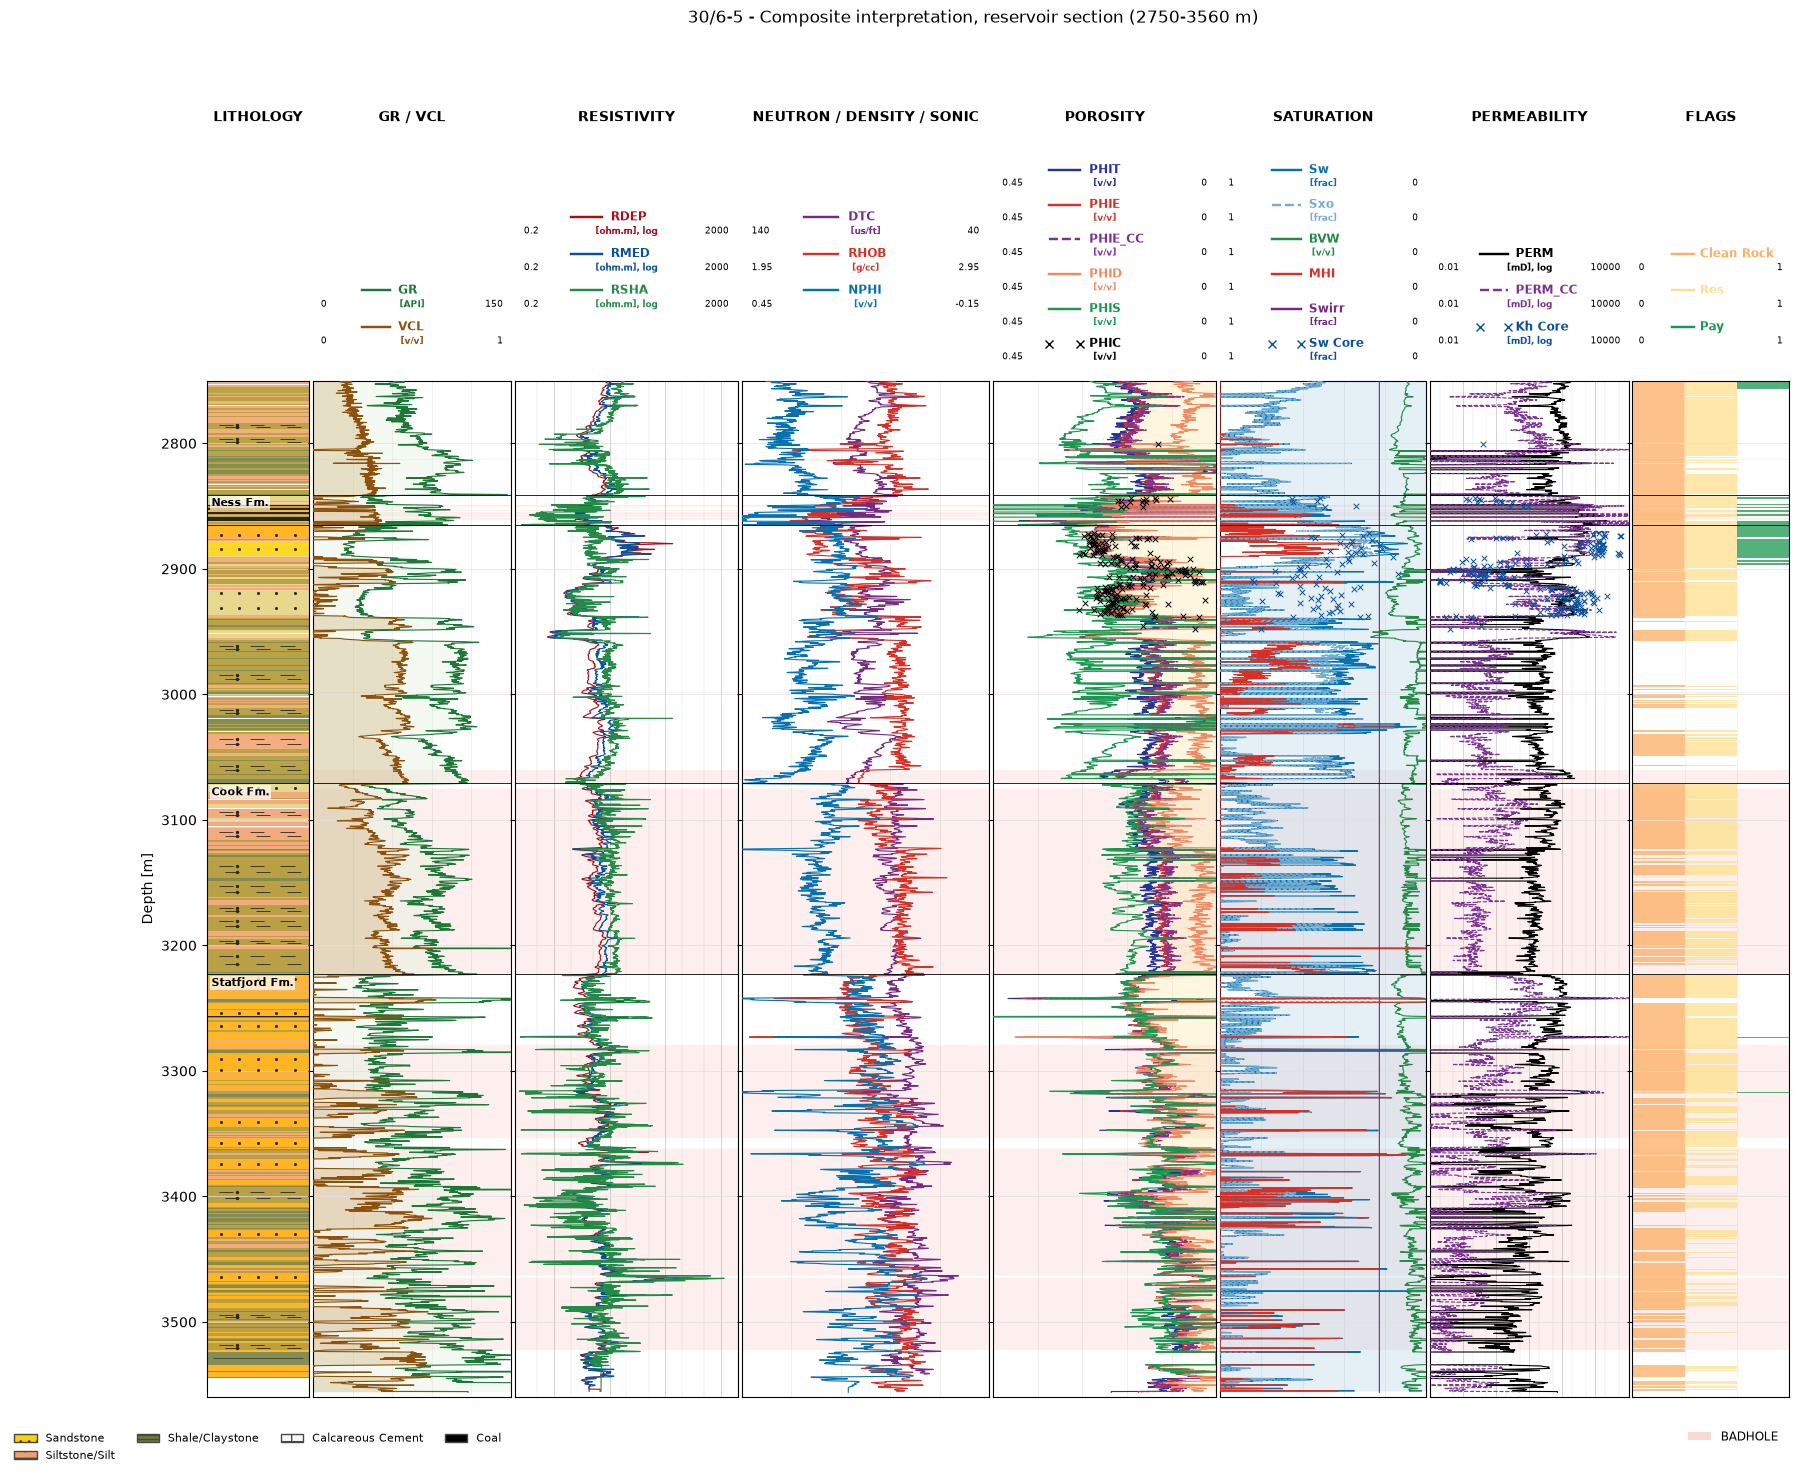

Labels hidden for spacing: ['Etive Fm.']


In [12]:
TOP, BOT = 2750.0, 3560.0

# Annotate the reservoir formations inside the window (the Brent Group top is the Ness top).
tops_table = pp.read_formations(TOPS, well=well)
marks = {
    row.formation_name: row.top_depth
    for row in tops_table.itertuples()
    if row.formation_name in RESERVOIR_FORMATIONS and TOP <= row.top_depth <= BOT
}

viewer = pp.plot(result, depth_range=(TOP, BOT), template="petrophysics", formation_tops=marks)
viewer.fig.suptitle(
    "30/6-5 - Composite interpretation, reservoir section ({:.0f}-{:.0f} m)".format(TOP, BOT),
    y=1.002, fontsize=12,
)
viewer.show()
viewer.close()
print("Labels hidden for spacing:",
      [item["name"] for item in viewer.diagnostics["suppressed_formation_labels"]] or "none")

## Part 6 - Interpretation and the deliverable

### What the numbers mean

Reading the tables and the plot together, 30/6-5 has **one strong reservoir package** - which is
exactly what the well's history says:

- **Etive Fm. (Brent Group).** The clean, blocky sand: the lowest Sw of the reservoir formations and
  the largest hydrocarbon pore thickness. This is the discovery.
- **Ness Fm. (Brent Group).** Real but poorer pay: thinner, with Sw closer to the cutoff. It sits
  directly on top of the Etive and is completed with it, not separately.
- **Statfjord Fm.** Only scattered flags at very low NTG, consistent with the NPD record, which
  reports no Statfjord discovery in this well. Not a target.
- **Cook Fm.** books little or nothing.
- **Everything else** - the overburden and the Viking Group mudstones - was set aside for the
  reasons given in Part 4.

The operator's 1981 evaluation (validated in lesson 09) reached the same conclusion with its own
zonation: pay in the Etive and Ness, nothing deeper. The next cell checks the Brent pay against the
NPD fact page, which reports oil from 2841 m down to 2899 m and an oil-water contact (OWC) at 2907 m
from pressure data.

In [13]:
NPD_OIL_TOP, NPD_OIL_BASE, NPD_OWC = 2841.0, 2899.0, 2907.0   # NPD fact page, 30/6-5

flagged = depth[brent_pay]
below_owc = pay & (depth > NPD_OWC) & (depth < BRENT_BASE)
print("Brent pay flags span      : {:.1f} - {:.1f} m".format(flagged.min(), flagged.max()))
print("NPD oil interval          : {:.0f} - {:.0f} m, OWC {:.0f} m".format(NPD_OIL_TOP, NPD_OIL_BASE, NPD_OWC))
print("Flagged pay below the OWC : {:.1f} m".format(below_owc.sum() * step))
agrees = below_owc.sum() == 0 and flagged.min() >= NPD_OIL_TOP
print("Log pay consistent with the NPD record:", agrees)

Brent pay flags span      : 2842.5 - 2897.3 m
NPD oil interval          : 2841 - 2899 m, OWC 2907 m
Flagged pay below the OWC : 0.0 m
Log pay consistent with the NPD record: True


### Deliverable (c): ranked candidate completion intervals

We build the ranking directly from the per-formation roll-up, scoring each pay-bearing reservoir
formation by hydrocarbon pore thickness (the volume proxy). The rationale for each row is derived
from its numbers with two simple rules, so it updates if the interpretation changes:

- a formation whose pay NTG is below 0.05 is **marginal** - scattered flags, not a completion target;
- otherwise the largest HCPV is the **primary target**, and other formations of the same group are
  completed with it.

In [14]:
MARGINAL_NTG = 0.05
parent_group = dict(zip(tops_table["formation_name"], tops_table["parent"]))

ranking = res_rows.copy()
viable = ranking[ranking["NTG"] >= MARGINAL_NTG]
primary = viable.iloc[0]["Formation"] if not viable.empty else None

def rationale(row):
    facts = "PHIE {:.2f}, Sw {:.2f}, perm {:.0f} mD, NTG {:.2f}".format(
        row["Avg PHIE"], row["Avg Sw"], row["Avg Perm (mD)"], row["NTG"])
    if row["NTG"] < MARGINAL_NTG:
        return "marginal - scattered flags ({}); do not perforate".format(facts)
    if row["Formation"] == primary:
        return "primary target - largest HCPV ({})".format(facts)
    if parent_group.get(row["Formation"]) and parent_group.get(row["Formation"]) == parent_group.get(primary):
        return "secondary - complete with {} ({})".format(primary, facts)
    return "secondary - separate appraisal ({})".format(facts)

print("=" * 92)
print("30/6-5  RANKED COMPLETION CANDIDATES")
print("=" * 92)
print("{:<3s} {:<14s} {:>13s} {:>8s} {:>7s} {:>7s} {:>9s} {:>7s}".format(
    "#", "Formation", "Interval(m)", "NetPay", "PHIE", "Sw", "Perm", "HCPV"))
print("-" * 92)
for i, row in ranking.iterrows():
    print("{:<3d} {:<14s} {:>6.0f}-{:<6.0f} {:>8.1f} {:>7.3f} {:>7.3f} {:>9.1f} {:>7.2f}".format(
        i + 1, row["Formation"], row["Top"], row["Bottom"], row[NET_PAY],
        row["Avg PHIE"], row["Avg Sw"], row["Avg Perm (mD)"], row["HCPV"]))
print("-" * 92)
print()
print("RATIONALE")
for i, row in ranking.iterrows():
    print("  {}. {:<14s} {}".format(i + 1, row["Formation"], rationale(row)))
print()
targets = viable[[r == primary or parent_group.get(r) == parent_group.get(primary)
                  for r in viable["Formation"]]]
relation = "above" if flagged.max() < NPD_OWC else "reaching below"
print("RECOMMENDATION: perforate {} ({:.0f}-{:.0f} m); pay flags span {:.1f}-{:.1f} m, "
      "{} the NPD OWC at {:.0f} m.".format(
          " + ".join(targets["Formation"]), targets["Top"].min(), targets["Bottom"].max(),
          flagged.min(), flagged.max(), relation, NPD_OWC))

30/6-5  RANKED COMPLETION CANDIDATES
#   Formation        Interval(m)   NetPay    PHIE      Sw      Perm    HCPV
--------------------------------------------------------------------------------------------
1   Etive Fm.        2865-2958       28.7   0.223   0.304     273.8    4.45
2   Ness Fm.         2841-2865       10.1   0.255   0.507     455.1    1.26
3   Statfjord Fm.    3223-3556        3.0   0.266   0.476     502.2    0.43
--------------------------------------------------------------------------------------------

RATIONALE
  1. Etive Fm.      primary target - largest HCPV (PHIE 0.22, Sw 0.30, perm 274 mD, NTG 0.31)
  2. Ness Fm.       secondary - complete with Etive Fm. (PHIE 0.25, Sw 0.51, perm 455 mD, NTG 0.42)
  3. Statfjord Fm.  marginal - scattered flags (PHIE 0.27, Sw 0.48, perm 502 mD, NTG 0.01); do not perforate

RECOMMENDATION: perforate Etive Fm. + Ness Fm. (2841-2958 m); pay flags span 2842.5-2897.3 m, above the NPD OWC at 2907 m.


**Recommendation in one line:** complete the **Brent Group sands (Ness + Etive)**, where the flagged
pay sits above the NPD's 2907 m OWC; the **Statfjord Fm.** carries only scattered, marginal flags
(the NPD records no Statfjord discovery here) and is not a completion candidate; the overburden
flags are not pay. One target, consistent with both the operator's 1981 evaluation and the NPD fact
page.

## Part 7 - Limitations and assumptions

An interpretation is only as trustworthy as its caveats. The material ones for 30/6-5:

- **The header Rw needed reconciliation, not blind trust.** The LAS parameter block states
  `RW = 0.70 ohm.m` with no temperature basis; at face value it wets out the entire well.
  Lesson 09's back-calculation of the operator's evaluation pins the working value at
  **0.070 ohm.m at 230 degF**, which we applied (`rw=0.070`, `rw_meas_temp_f=230`). Sw scales
  roughly with `sqrt(Rw)`, so this is the single biggest lever on the answer; case study **CS5**
  quantifies it.
- **The overburden is the failure mode to watch - and on this well it fires.** The unconsolidated
  Nordland/Hordaland sediments read very high porosity, the minimum-of-three clay indicator reads
  them clean, and the brine-calibrated Rw lets Sw fall just under the cutoff, so a large thickness
  of shallow section is flagged (printed in Part 4). Restricting the evaluation to named reservoir
  formations is what keeps it out of the answer.
- **PEF only over a narrow window.** Lithology discrimination is best where PEF is live (the window
  printed in Part 2); outside it the multi-mineral solve leans on density-neutron alone. That
  applies not just to the shallow section but also to most of the Statfjord, so the mineral volumes
  there carry extra uncertainty.
- **Groups and formations overlap.** The bundled tops nest formations inside groups.
  `formation_summary(rank="formation")` (or `rank="group"`) picks one level so no depth is counted
  twice; never add rows from both levels.
- **One whole-well core calibration.** The tops were kept out of `pp.interpret`, so core porosity and
  permeability are calibrated with all core points at once rather than formation by formation. Ness
  has only a few core points of its own.
- **Cutoffs are conventions.** `Vcl < 0.40`, `PHIE > 0.08`, `Sw < 0.60` are reasonable clastic
  defaults but are choices; moving them moves the net-pay totals. They are set explicitly above so
  they can be challenged.
- **HCPV here is a thickness index**, not a volumetric OOIP. It ranks zones per unit area; a true
  volumetric estimate needs area and formation-volume factor
  (`petrophys.evaluation.summaries.calculate_ooip`).

## Part 8 - Appendix: reproduce this on another well, and hand off the results

The whole evaluation is one `pp.interpret` call plus one formation roll-up, so it fits in a small
function. To re-run on a different well, swap the file, the tops and - critically - the settings:
header parameters where the LAS carries them (as here), basin-appropriate assumptions where it does
not. We re-run 30/6-5 through the function to confirm it reproduces the table, then write the
hand-off files a reviewer needs: the interpreted LAS (settings recorded as `PP_*` header
parameters), the full JSON trace, and the formation table.

In [15]:
def evaluate_well(path, tops, reservoir_formations, **settings):
    """Read -> interpret -> per-formation table restricted to the reservoir formations."""
    interpretation = pp.interpret(pp.read(path), **settings).raise_for_errors()
    summary = interpretation.formation_summary(tops, rank="formation")
    return interpretation, summary[summary["Formation"].isin(reservoir_formations)]

rerun, rerun_table = evaluate_well(pp.sample("30_6-5"), TOPS, RESERVOIR_FORMATIONS, **SETTINGS)
same = np.allclose(rerun_table[NET_PAY].to_numpy(), fm_table.loc[is_reservoir, NET_PAY].to_numpy())
print("Re-run reproduces the reservoir net pay:", same)

# Hand-off files (written to the current working directory).
las_file = result.to_las("30_6-5_interpreted.las")
trace_file = result.to_json("30_6-5_trace.json")
fm_table.to_csv("30_6-5_formation_summary.csv", index=False)
print("Wrote:", las_file.name, "|", trace_file.name, "| 30_6-5_formation_summary.csv")

Re-run reproduces the reservoir net pay: True


Wrote: 30_6-5_interpreted.las | 30_6-5_trace.json | 30_6-5_formation_summary.csv


#### Applying this workflow to another well

Start with `pp.read` and `pp.plot` on the LAS alone. Add optional formation/lithology tables only
when available, using the [input templates](../../docs/input_templates.md). Formation analysis
requires bounded intervals or a justified terminal depth.

Then use `pp.interpret` with well-specific fluid, temperature and rock assumptions - always state the
temperature at which Rw applies. Inspect the trace, source selection, warnings and skipped steps
before interpreting the computed curves, check where the pay flag fires, and quote pay only over the
reservoir interval. The case-study parameters are not universal defaults.

### Recap

- We ran a full, auditable formation evaluation of discovery well 30/6-5 with one `pp.interpret`
  call and used its **step trace** as the interpretation audit.
- We checked **where the pay flag fired** before trusting totals: the Brent block is the discovery;
  the overburden flags are artefacts of soft, high-porosity sediment and a brine-calibrated Rw, and
  are removed by scoping the evaluation to reservoir formations.
- `result.formation_summary(TOPS, rank="formation")` gave the per-formation table without
  double-counting nested groups, and fed the three deliverables: a per-formation table, a composite
  plot and a **ranked completion plan**.
- The verdict: perforate the **Brent Group (Ness + Etive) sands** - the only real target, with the
  pay above the NPD's OWC. The Statfjord carries only scattered, marginal flags.
- The environment came from the **LAS header parameter block**, with one documented reconciliation:
  Rw 0.070 ohm.m at 230 degF (lesson 09).

### Exercises

1. **Default settings.** Run `pp.interpret(well, rw=0.07, rw_meas_temp_f=230)` with no other
   settings and compare `formation_summary(TOPS, rank="group")` with the group table in Part 4.
   Which groups change most, and which step decisions explain it?
2. **Cutoff sensitivity.** Re-run with `sw_cutoff=0.5`. How do the Etive and Ness net pay respond,
   and how does the overburden respond? What does that tell you about using a tighter cutoff as a
   cure for the shallow flags?
3. **Formation-specific calibration.** Read the well with
   `pp.read(pp.sample("30_6-5"), formations=TOPS)` and interpret it with the same `SETTINGS`; the
   `input_context` and `core_correction` decisions list the per-group and per-formation core
   models. Then attach one level only with `formation_options={"rank": "formation"}` and
   interpret again. Compare the Ness row of the formation table across the three runs. Which
   calibration would you defend, given how few core points Ness has?

### What's next

**CS2** moves to a carbonate: core-calibrated rock typing over the Kharaib-2 interval of a COSTA
well. **CS5** returns to 30/6-5 to quantify how the saturation model and its parameters move the
Brent answer.